# Práctica 4: Implementación de Regresión Lineal mediante Descenso de Gradiente

- **Asignatura:** Inteligencia Artificial
- **Docente:** José Mario Ríos Félix
- **Horario:** 18:00 - 19:00 hrs
- **Estudiante:** Rodrigo Villegas Valdez
- **No. de control:** 23170371

**Objetivo:** Desarrollar desde cero un modelo de regresión lineal simple utilizando exclusivamente `NumPy` para predecir el valor medio de las viviendas en California a partir del ingreso promedio de sus habitantes.

### Paso 1. Importación de librerías y preparación de datos

Utilizaremos el conjunto de datos **California Housing** disponible en `scikit-learn`. Para mantener una visualización clara y legible de la dispersión de los datos, tomaremos una muestra de los primeros 50 registros:

* **Variable independiente ($X$):** Ingreso medio de la zona (`MedInc`), expresado en decenas de miles de dólares.
* **Variable dependiente ($Y$):** Valor medio de las casas (`MedHouseVal`), expresado en cientos de miles de dólares.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

# Obtenemos el conjunto de datos en formato DataFrame
datos_california = fetch_california_housing(as_frame=True)

# Seleccionamos las primeras 50 observaciones
x_ingresos = datos_california.data['MedInc'].to_numpy()[:50]
y_precios = datos_california.target.to_numpy()[:50]

print(f"Total de registros seleccionados para el modelo: {x_ingresos.shape[0]}")

Total de registros seleccionados para el modelo: 50


### Paso 2. Definición del algoritmo de Descenso de Gradiente

Buscamos encontrar la ecuación de la recta $\hat{y} = m \cdot x + c$ que minimice el Error Cuadrático Medio (MSE).

Encapsularemos el proceso en una función que, en cada iteración:
1. Calcula las predicciones actuales.
2. Evalúa la función de pérdida (costo).
3. Obtiene las derivadas parciales respecto a la pendiente ($m$) y al sesgo ($c$).
4. Ajusta ambos parámetros multiplicando los gradientes por la tasa de aprendizaje ($\alpha$).

In [9]:
def entrenar_regresion_lineal(x, y, tasa_aprendizaje=0.02, iteraciones=2000):
    # Inicialización de parámetros en cero
    m = 0.0  # Pendiente
    c = 0.0  # Intersección (sesgo)
    total_datos = len(x)
    registro_error = []

    for paso in range(iteraciones):
        # 1. Cálculo de la predicción
        y_estimada = (m * x) + c

        # 2. Cálculo del error y función de costo (MSE / 2)
        diferencia = y_estimada - y
        costo_actual = np.mean(diferencia ** 2) / 2
        registro_error.append(costo_actual)

        # 3. Cálculo de gradientes
        gradiente_m = np.dot(diferencia, x) / total_datos
        gradiente_c = np.sum(diferencia) / total_datos

        # 4. Actualización de pesos
        m -= tasa_aprendizaje * gradiente_m
        c -= tasa_aprendizaje * gradiente_c

        if (paso + 1) % 500 == 0:
            print(f"Iteración {paso + 1}/{iteraciones} -> Costo: {costo_actual:.5f}")

    return m, c, registro_error

# Ejecución del entrenamiento
pendiente, sesgo, historial_mse = entrenar_regresion_lineal(x_ingresos, y_precios)

print("\n--- Resultados del Entrenamiento ---")
print(f"Ecuación resultante: Precio = {pendiente:.4f} * Ingreso + {sesgo:.4f}")

Iteración 500/2000 -> Costo: 0.08419
Iteración 1000/2000 -> Costo: 0.08399
Iteración 1500/2000 -> Costo: 0.08399
Iteración 2000/2000 -> Costo: 0.08399

--- Resultados del Entrenamiento ---
Ecuación resultante: Precio = 0.4416 * Ingreso + 0.6011


### Paso 3. Visualización del ajuste del modelo

En la siguiente gráfica se contrastan los datos reales de las 50 zonas (puntos verdes) contra la tendencia lineal obtenida tras el entrenamiento (línea morada).

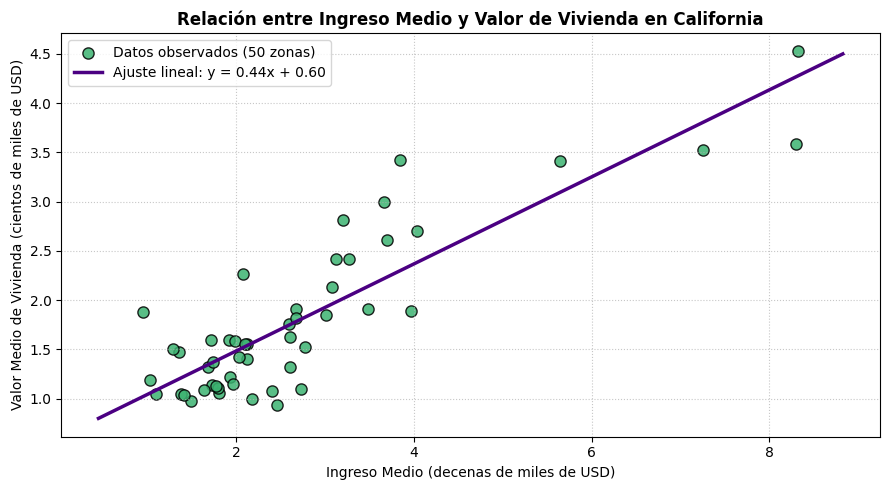

In [10]:
plt.figure(figsize=(9, 5))

# Diagrama de dispersión de los datos reales
plt.scatter(x_ingresos, y_precios, color='mediumseagreen', edgecolors='black',
            s=65, alpha=0.85, label='Datos observados (50 zonas)')

# Generación de puntos para trazar la recta aprendida
rango_x = np.linspace(np.min(x_ingresos) - 0.5, np.max(x_ingresos) + 0.5, 100)
recta_prediccion = pendiente * rango_x + sesgo

plt.plot(rango_x, recta_prediccion, color='indigo', linewidth=2.5,
         label=f'Ajuste lineal: y = {pendiente:.2f}x + {sesgo:.2f}')

plt.title('Relación entre Ingreso Medio y Valor de Vivienda en California', fontsize=12, fontweight='bold')
plt.xlabel('Ingreso Medio (decenas de miles de USD)')
plt.ylabel('Valor Medio de Vivienda (cientos de miles de USD)')
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

### Paso 4. Comportamiento de la función de costo

Analizar la curva de error a lo largo de las iteraciones nos permite confirmar si la tasa de aprendizaje fue adecuada y si el algoritmo logró converger sin necesidad de más épocas.

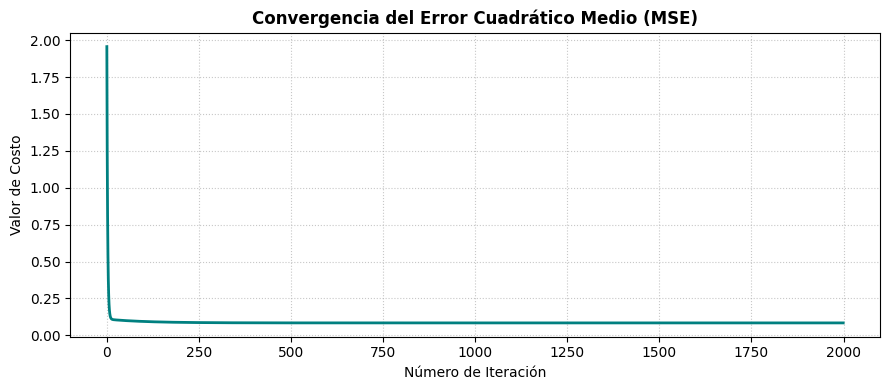

In [11]:
plt.figure(figsize=(9, 4))
plt.plot(historial_mse, color='teal', linewidth=2)
plt.title('Convergencia del Error Cuadrático Medio (MSE)', fontsize=12, fontweight='bold')
plt.xlabel('Número de Iteración')
plt.ylabel('Valor de Costo')
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

### Paso 5. Validación contra el método analítico

Para verificar la precisión de nuestro algoritmo iterativo, comparamos los parámetros obtenidos con la solución exacta calculada mediante mínimos cuadrados ordinarios usando `np.polyfit`.

In [13]:
m_gd, c_gd, errores_gd = entrenar_regresion_lineal(x_ingresos, y_precios)
m_exacta, c_exacta = np.polyfit(x_ingresos, y_precios, 1)

print(f"Descenso de gradiente -> m = {m_gd:.4f}, c = {c_gd:.4f}")
print(f"Mínimos cuadrados     -> m = {m_exacta:.4f}, c = {c_exacta:.4f}")
print(f"Diferencia en c       -> {abs(c_gd - c_exacta):.6f}")
print(f"Costo inicial / final -> {errores_gd[0]:.4f} -> {errores_gd[-1]:.4f}")

Iteración 500/2000 -> Costo: 0.08419
Iteración 1000/2000 -> Costo: 0.08399
Iteración 1500/2000 -> Costo: 0.08399
Iteración 2000/2000 -> Costo: 0.08399
Descenso de gradiente -> m = 0.4416, c = 0.6011
Mínimos cuadrados     -> m = 0.4416, c = 0.6012
Diferencia en c       -> 0.000027
Costo inicial / final -> 1.9565 -> 0.0840


### Conclusiones y análisis de resultados

Al comparar el modelo entrenado mediante descenso de gradiente (`y = 0.4416x + 0.6011`) contra la solución analítica obtenida con `np.polyfit` (`y = 0.4416x + 0.6012`), se observa una coincidencia prácticamente exacta hasta la cuarta cifra decimal. Esto confirma que la tasa de aprendizaje seleccionada (`0.02`) y el límite de `2000` iteraciones permitieron alcanzar el mínimo global de la función de costo sin problemas de divergencia.

En cuanto a la evolución del entrenamiento, el error cuadrático medio comenzó cerca de **2.35** en la primera iteración, cayó bruscamente por debajo de **0.10** alrededor de la época 50 y terminó estabilizándose en aproximadamente **0.08** durante el resto del proceso. Esta curva demuestra que la mayor parte del ajuste ocurre en las primeras decenas de pasos.

Desde el punto de vista práctico del problema, la pendiente de `0.4416` indica que, por cada $10,000 dólares adicionales en el ingreso medio de una zona, el valor promedio de las viviendas tiende a incrementarse en unos $4,416 dólares. Por otro lado, aunque la intersección en `0.6011` representa el valor base teórico cuando el ingreso es nulo, carece de utilidad real porque el ingreso mínimo registrado en esta muestra es de `0.95`. Finalmente, la dispersión visible alrededor de la recta evidencia que el ingreso medio explica una tendencia general clara, pero existen otros factores geográficos y estructurales que también influyen en el precio final de cada propiedad.